# Granite Embedding 748M Vision R2: examples

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ibm-granite/granite-embedding-models/blob/main/code/granite_embedding_748m_vision_r2_examples.ipynb)

[granite-embedding-748m-vision-r2](https://huggingface.co/ibm-granite/granite-embedding-748m-vision-r2) retrieves document pages directly from their images, with no OCR pipeline. One forward pass gives two embeddings: a **768-d single vector** per query or page, and **128-d multi-vectors** (one per token) scored with late interaction (MaxSim).

This notebook walks through:

1. Multi-vector search (MaxSim)
2. Single-vector search, and Matryoshka truncation
3. Hybrid search: single-vector shortlist, multi-vector rerank
4. Queries in other languages, and simulated scans
5. Where the query looks: the elephant example
6. Text passages and page images in one index
7. Index size: token pooling and int8
8. Encoding speed, and how it compares with other models

**Runtime:** a GPU is recommended (in Colab: *Runtime → Change runtime type → T4 GPU* or better). Ampere and newer GPUs (L4, A100, H100) run the model in bf16; older ones such as the T4 run it in float32. A CPU works, but slowly.

In [ ]:
%pip install -q -U "sentence-transformers>=6" pillow matplotlib scipy

## Setup

Load the model and the example pages: four one-page business documents in four languages (an English quarterly report, a French travel policy, a Spanish invoice and a Japanese product sheet), an encyclopedia drawing of an elephant, and a bedroom photograph. Simulated scans of the four documents are used in section 4.

In [18]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from huggingface_hub import snapshot_download
from PIL import Image
from sentence_transformers import MultiVectorEncoder

# MODEL_ID = os.environ.get("GRANITE_VISION_MODEL", "ibm-granite/granite-embedding-748m-vision-r2")
MODEL_ID = os.environ.get("GRANITE_VISION_MODEL", "perplexity-ai/pplx-embed-v2-late-0.6b")

device = "cuda" if torch.cuda.is_available() else "cpu"
# bf16 needs an Ampere or newer GPU; older GPUs (such as the T4) and CPUs use float32.
dtype = torch.bfloat16 if device == "cuda" and torch.cuda.get_device_capability()[0] >= 8 else torch.float32

model = MultiVectorEncoder(MODEL_ID, trust_remote_code=True, device=device, model_kwargs={"dtype": dtype})
processor = model[0].processor
tokenizer = processor.tokenizer
print(f"{MODEL_ID} on {device} ({dtype}), {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

KeyboardInterrupt: 

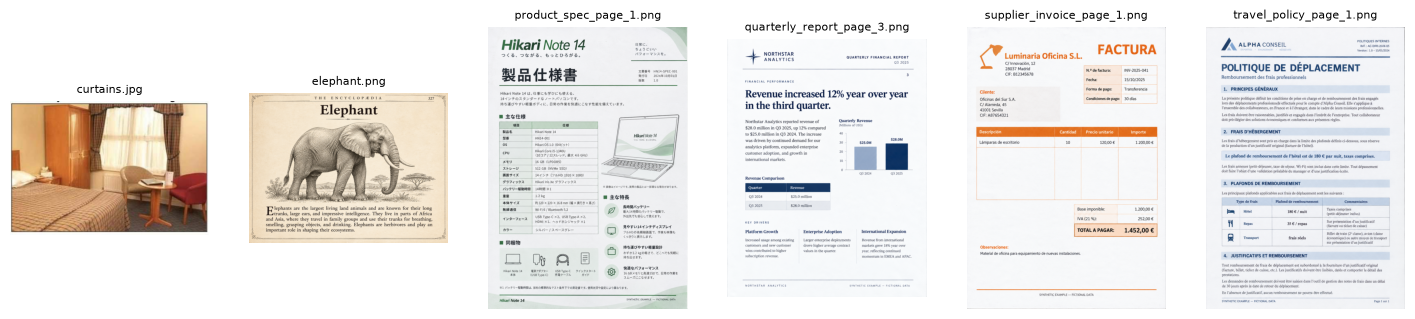

In [3]:
# The example pages ship with the model repository; a local images/ folder is used instead if there is one.
if Path("images").is_dir():
    root = Path(".")
else:
    root = Path(snapshot_download(MODEL_ID, allow_patterns=["images/*", "degraded-images/*"]))


def load_pages(folder):
    return {p.name: Image.open(p).convert("RGB")
            for p in sorted((root / folder).iterdir()) if p.suffix.lower() in {".png", ".jpg", ".jpeg"}}


pages = load_pages("images")
page_names = list(pages)

fig, axes = plt.subplots(1, len(pages), figsize=(3 * len(pages), 4))
for ax, (name, page) in zip(axes, pages.items()):
    ax.imshow(page)
    ax.set_title(name, fontsize=8)
    ax.axis("off")
plt.show()

## 1. Multi-vector search (MaxSim)

`encode_query` and `encode_document` with `output_value=None` return everything from one forward pass: the token ids, the per-token multi-vectors and the single vector. The multi-vectors are padded to the length of the longest input in the batch, so keep only the real tokens (`attention_mask`); padding vectors would inflate MaxSim scores.

MaxSim scores a query against a page by taking, for each query token, its best dot product with any page token, and adding those maxima up.

In [4]:
def encode(items, kind):
    """Encode queries (kind="query") or pages/passages (kind="document"); returns multi-vectors, single vectors, token ids."""
    encode_fn = model.encode_query if kind == "query" else model.encode_document
    with torch.inference_mode():
        outputs = encode_fn(items, output_value=None)
    keep = [o["attention_mask"].bool() for o in outputs]
    multi = [o["token_embeddings"][k].float().cpu() for o, k in zip(outputs, keep)]
    single = torch.stack([o["sentence_embedding"] for o in outputs]).float().cpu()
    ids = [o["input_ids"][k].cpu() for o, k in zip(outputs, keep)]
    return multi, single, ids


def maxsim(query_multi, doc_multi):
    """MaxSim scores, shape (queries, documents)."""
    return torch.tensor([[(q @ d.T).max(dim=1).values.sum().item() for d in doc_multi] for q in query_multi])


def show_ranking(title, queries, scores, names, expected=None, top=3, fmt=".2f"):
    print(f"=== {title}")
    for i, query in enumerate(queries):
        print(f"{query}")
        for rank, j in enumerate(scores[i].argsort(descending=True)[:top].tolist(), start=1):
            mark = "✓" if expected and names[j] == expected[i] else " "
            print(f"  {mark} {rank}. {names[j]:<30} {scores[i, j]:{fmt}}")
    print()


page_multi, page_single, page_ids = encode(list(pages.values()), "document")
print("Vectors per page:", {name: len(v) for name, v in zip(page_names, page_multi)})
print("Multi-vector width:", page_multi[0].shape[1], "| single vector width:", page_single.shape[1])

Vectors per page: {'curtains.jpg': 229, 'elephant.png': 683, 'product_spec_page_1.png': 589, 'quarterly_report_page_3.png': 547, 'supplier_invoice_page_1.png': 589, 'travel_policy_page_1.png': 589}
Multi-vector width: 128 | single vector width: 768


In [5]:
# Each query in the language of its page, plus two questions about the pictures.
queries = {
    "How much did revenue grow in the third quarter?": "quarterly_report_page_3.png",
    "Quel est le plafond pour l'hôtel ?": "travel_policy_page_1.png",
    "¿Cuál es el importe total de la factura?": "supplier_invoice_page_1.png",
    "この製品のバッテリー駆動時間は何時間ですか？": "product_spec_page_1.png",
    "What do elephants use their trunks and tusks for?": "elephant.png",
    "What pattern are the curtains in the bedroom?": "curtains.jpg",
}
query_texts, expected = list(queries), list(queries.values())
query_multi, query_single, query_ids = encode(query_texts, "query")

mv_scores = maxsim(query_multi, page_multi)
# model.similarity computes the same MaxSim scores.
assert torch.allclose(mv_scores, torch.as_tensor(model.similarity(query_multi, page_multi)).float(), atol=1e-2)
show_ranking("Multi-vector (MaxSim)", query_texts, mv_scores, page_names, expected)

=== Multi-vector (MaxSim)
How much did revenue grow in the third quarter?
  ✓ 1. quarterly_report_page_3.png    9.63
    2. supplier_invoice_page_1.png    7.25
    3. travel_policy_page_1.png       7.03
Quel est le plafond pour l'hôtel ?
  ✓ 1. travel_policy_page_1.png       7.93
    2. curtains.jpg                   7.24
    3. supplier_invoice_page_1.png    6.44
¿Cuál es el importe total de la factura?
  ✓ 1. supplier_invoice_page_1.png    9.06
    2. travel_policy_page_1.png       7.84
    3. quarterly_report_page_3.png    7.27
この製品のバッテリー駆動時間は何時間ですか？
  ✓ 1. product_spec_page_1.png        8.56
    2. curtains.jpg                   6.47
    3. supplier_invoice_page_1.png    6.39
What do elephants use their trunks and tusks for?
  ✓ 1. elephant.png                   10.19
    2. curtains.jpg                   7.69
    3. product_spec_page_1.png        7.57
What pattern are the curtains in the bedroom?
  ✓ 1. curtains.jpg                   8.23
    2. travel_policy_page_1.png       6.26

## 2. Single-vector search, and Matryoshka truncation

The single vector is the L2-normalized `[CLS]` embedding, scored with cosine similarity, so it works in any vector database. It was trained with Matryoshka representation learning: its first 128, 256, 384 or 512 dimensions, re-normalized, are a smaller embedding of the same input.

In [6]:
sv_scores = query_single @ page_single.T
show_ranking("Single vector (cosine), 768-d", query_texts, sv_scores, page_names, expected, fmt=".3f")


def truncate(vectors, dims):
    return torch.nn.functional.normalize(vectors[:, :dims], dim=-1)


print("Correct page ranked first, by single-vector size:")
for dims in (768, 512, 384, 256, 128):
    scores = truncate(query_single, dims) @ truncate(page_single, dims).T
    correct = sum(page_names[j] == e for j, e in zip(scores.argmax(dim=1).tolist(), expected))
    print(f"  {dims:>3}-d ({dims * 2:>4} bytes in fp16): {correct}/{len(expected)}")

=== Single vector (cosine), 768-d
How much did revenue grow in the third quarter?
  ✓ 1. quarterly_report_page_3.png    0.866
    2. supplier_invoice_page_1.png    0.667
    3. travel_policy_page_1.png       0.635
Quel est le plafond pour l'hôtel ?
    1. curtains.jpg                   0.754
  ✓ 2. travel_policy_page_1.png       0.733
    3. supplier_invoice_page_1.png    0.677
¿Cuál es el importe total de la factura?
  ✓ 1. supplier_invoice_page_1.png    0.826
    2. travel_policy_page_1.png       0.732
    3. quarterly_report_page_3.png    0.690
この製品のバッテリー駆動時間は何時間ですか？
  ✓ 1. product_spec_page_1.png        0.752
    2. supplier_invoice_page_1.png    0.619
    3. curtains.jpg                   0.610
What do elephants use their trunks and tusks for?
  ✓ 1. elephant.png                   0.812
    2. curtains.jpg                   0.634
    3. product_spec_page_1.png        0.616
What pattern are the curtains in the bedroom?
  ✓ 1. curtains.jpg                   0.850
    2. product_spec

## 3. Hybrid search: single-vector shortlist, multi-vector rerank

For a large collection, search the single-vector index for a shortlist, then rerank only the shortlist with MaxSim. The multi-vector scores often separate pages that are close under the single vector, and can fix its mistakes: check the French hotel question above, where the single vector can rank another page first. With six pages the shortlist here is 2; a real collection would rerank about 100.

In [7]:
SHORTLIST = 2

print(f"=== Single-vector top {SHORTLIST}, reranked with MaxSim")
for i, query in enumerate(query_texts):
    shortlist = sv_scores[i].argsort(descending=True)[:SHORTLIST].tolist()
    reranked = sorted(shortlist, key=lambda j: mv_scores[i, j].item(), reverse=True)
    print(query)
    for j in reranked:
        mark = "✓" if page_names[j] == expected[i] else " "
        print(f"  {mark} {page_names[j]:<30} cosine {sv_scores[i, j]:.3f}   MaxSim {mv_scores[i, j]:.2f}")

=== Single-vector top 2, reranked with MaxSim
How much did revenue grow in the third quarter?
  ✓ quarterly_report_page_3.png    cosine 0.866   MaxSim 9.63
    supplier_invoice_page_1.png    cosine 0.667   MaxSim 7.25
Quel est le plafond pour l'hôtel ?
  ✓ travel_policy_page_1.png       cosine 0.733   MaxSim 7.93
    curtains.jpg                   cosine 0.754   MaxSim 7.24
¿Cuál es el importe total de la factura?
  ✓ supplier_invoice_page_1.png    cosine 0.826   MaxSim 9.06
    travel_policy_page_1.png       cosine 0.732   MaxSim 7.84
この製品のバッテリー駆動時間は何時間ですか？
  ✓ product_spec_page_1.png        cosine 0.752   MaxSim 8.56
    supplier_invoice_page_1.png    cosine 0.619   MaxSim 6.39
What do elephants use their trunks and tusks for?
  ✓ elephant.png                   cosine 0.812   MaxSim 10.19
    curtains.jpg                   cosine 0.634   MaxSim 7.69
What pattern are the curtains in the bedroom?
  ✓ curtains.jpg                   cosine 0.850   MaxSim 8.23
    product_spec_page_1.png 

## 4. Queries in other languages, and simulated scans

The text encoder is multilingual, so a query need not be in the language of the page. Below, each document is asked about in a different language. Then the same-language queries are run against simulated scans of the pages (light noise, softness and skew).

In [8]:
cross_language = {
    "Um wie viel Prozent ist der Umsatz im dritten Quartal gestiegen?": "quarterly_report_page_3.png",  # German → English page
    "What is the maximum hotel reimbursement per night?": "travel_policy_page_1.png",                  # English → French page
    "この請求書の支払総額はいくらですか？": "supplier_invoice_page_1.png",                                # Japanese → Spanish page
    "Quelle est l'autonomie de la batterie de cet ordinateur portable ?": "product_spec_page_1.png",   # French → Japanese page
}
cross_multi, _, _ = encode(list(cross_language), "query")
show_ranking("Cross-language, multi-vector", list(cross_language), maxsim(cross_multi, page_multi),
             page_names, list(cross_language.values()))

scans = load_pages("degraded-images")
scan_names = list(scans)
scan_multi, _, _ = encode(list(scans.values()), "document")
document_queries = [q for q, page in queries.items() if page in scans]
document_multi = [query_multi[query_texts.index(q)] for q in document_queries]
original = maxsim(document_multi, [page_multi[page_names.index(n)] for n in scan_names])
scanned = maxsim(document_multi, scan_multi)
show_ranking("Same-language queries against the simulated scans", document_queries, scanned,
             scan_names, [queries[q] for q in document_queries])
print(f"Largest change in any MaxSim score from original to scan: {(scanned - original).abs().max():.3f}")

=== Cross-language, multi-vector
Um wie viel Prozent ist der Umsatz im dritten Quartal gestiegen?
  ✓ 1. quarterly_report_page_3.png    12.16
    2. supplier_invoice_page_1.png    9.45
    3. product_spec_page_1.png        8.98
What is the maximum hotel reimbursement per night?
  ✓ 1. travel_policy_page_1.png       8.00
    2. curtains.jpg                   6.72
    3. product_spec_page_1.png        6.54
この請求書の支払総額はいくらですか？
  ✓ 1. supplier_invoice_page_1.png    8.89
    2. travel_policy_page_1.png       7.40
    3. product_spec_page_1.png        6.94
Quelle est l'autonomie de la batterie de cet ordinateur portable ?
  ✓ 1. product_spec_page_1.png        11.66
    2. curtains.jpg                   9.68
    3. supplier_invoice_page_1.png    9.41

=== Same-language queries against the simulated scans
How much did revenue grow in the third quarter?
  ✓ 1. quarterly_report_page_3.png    9.62
    2. supplier_invoice_page_1.png    7.31
    3. travel_policy_page_1.png       7.01
Quel est le pla

## 5. Where does the query look? The elephant example

Every visual token of a page comes from a known cell of the page: the connector emits rows of cells in reading order, with a newline token ending each row. So for each query token, the page token that wins its MaxSim maximum can be drawn on the page.

The left panel shows where each query token found its best match, numbered in query order. The other panels show how similar one query token is to every cell of the page. Read them as a view into the scoring, not as text detection: page tokens pass through the text encoder and carry context from around the page, so a match can land next to the words or drawing it refers to.

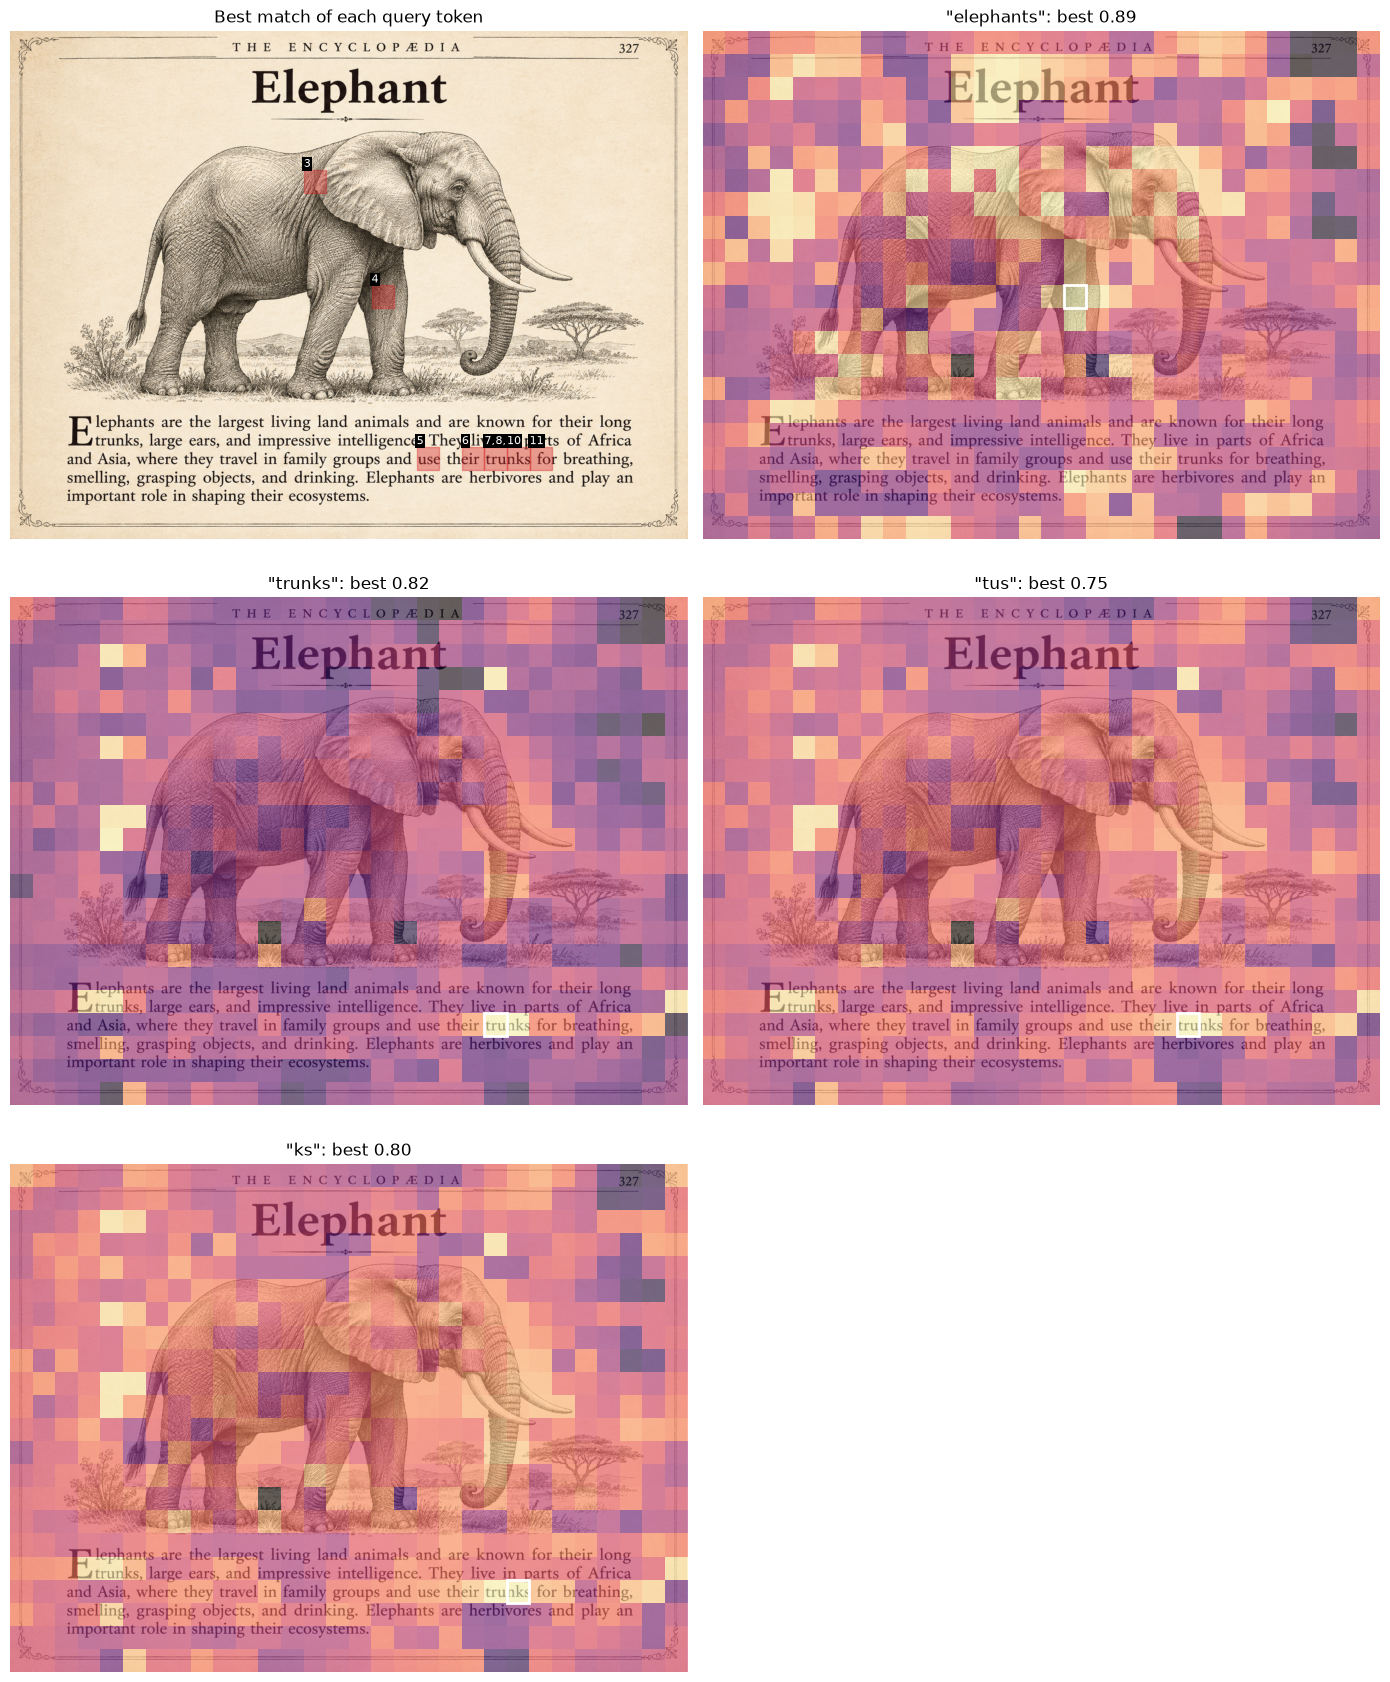

Query tokens: 1 <bos>, 2 What, 3 do, 4 elephants, 5 use, 6 their, 7 trunks, 8 and, 9 tus, 10 ks, 11 for, 12 ?
Best match on a token with no place on the page (start or row-end token): ['<bos>', 'What', '?']


In [9]:
from matplotlib.patches import Rectangle

image_processor = processor.image_processor


def page_grid(page, token_ids):
    """Grid size of a page, and the (row, col) cell of each page token (None for tokens with no place on the page)."""
    patch_h, patch_w = (int(s) for s in image_processor([page])["spatial_shapes"][0])
    query_side, window_side = (int(s) for s in image_processor.downsample_rate.split("/"))
    rows, cols = patch_h * query_side // window_side, patch_w * query_side // window_side
    row_length = cols + int(processor.use_image_newline)
    positions = (token_ids == processor.image_token_id).nonzero().squeeze(-1).tolist()
    cells = [None] * len(token_ids)
    for offset, position in enumerate(positions):
        row, col = divmod(offset, row_length)
        if col < cols:  # the last token of each row is the newline
            cells[position] = (row, col)
    return rows, cols, cells


def show_query_on_page(query, page_name, show_tokens):
    (q,), _, (q_ids,) = encode([query], "query")
    d, ids, page = page_multi[page_names.index(page_name)], page_ids[page_names.index(page_name)], pages[page_name]
    rows, cols, cells = page_grid(page, ids)
    similarity = q @ d.T  # query tokens × page tokens
    best = similarity.argmax(dim=1).tolist()
    labels = [t.replace("▁", "") for t in tokenizer.convert_ids_to_tokens(q_ids.tolist())]
    width, height = page.size
    cell_w, cell_h = width / cols, height / rows

    panels = 1 + len(show_tokens)
    ncols = min(panels, 2 if width > height else 3)
    nrows = -(-panels // ncols)
    panel_w = 7 if width > height else 5
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel_w * ncols, (panel_w * height / width + 0.5) * nrows), squeeze=False)
    axes = axes.ravel()
    for ax in axes[panels:]:
        ax.remove()
    axes = axes[:panels]
    axes[0].imshow(page)
    axes[0].set_title("Best match of each query token")
    numbers = {}
    for i, token in enumerate(best):
        if cells[token] is not None:
            numbers.setdefault(cells[token], []).append(str(i + 1))
    for (row, col), nums in numbers.items():
        axes[0].add_patch(Rectangle((col * cell_w, row * cell_h), cell_w, cell_h, color="tab:red", alpha=0.4))
        axes[0].text(col * cell_w, row * cell_h, ",".join(nums), fontsize=8, color="white", va="bottom",
                     bbox=dict(facecolor="black", pad=1, linewidth=0))

    for ax, label in zip(axes[1:], show_tokens):
        t = labels.index(label)
        heat = np.full((rows, cols), np.nan)
        for token, cell in enumerate(cells):
            if cell is not None:
                heat[cell] = similarity[t, token].item()
        ax.imshow(page)
        ax.imshow(heat, extent=(0, width, height, 0), cmap="magma", alpha=0.6)
        if cells[best[t]] is not None:
            row, col = cells[best[t]]
            ax.add_patch(Rectangle((col * cell_w, row * cell_h), cell_w, cell_h, fill=False, edgecolor="white", linewidth=2))
        # matplotlib's default font has no CJK glyphs, so non-ASCII tokens are named by their number.
        name = f'"{label}"' if label.isascii() else f"token {t + 1}"
        ax.set_title(f"{name}: best {similarity[t].max():.2f}")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    print("Query tokens:", ", ".join(f"{i + 1} {label}" for i, label in enumerate(labels)))
    no_place = [labels[i] for i, token in enumerate(best) if cells[token] is None]
    print("Best match on a token with no place on the page (start or row-end token):", no_place or "none")


show_query_on_page("What do elephants use their trunks and tusks for?", "elephant.png", ["elephants", "trunks", "tus", "ks"])

In [ ]:
# The same view for a cross-language query: a Japanese question about the Spanish invoice.
show_query_on_page("この請求書の支払総額はいくらですか？", "supplier_invoice_page_1.png", ["支払", "総"])

## 6. Text passages and page images in one index

Text passages are encoded with the same `encode_document` call. Encode images and text in separate calls (one modality per call), then put them in one index: a query gets one ranked list of passages and pages. A passage that states the answer outright usually scores above the page that shows it.

In [10]:
passages = [
    "Revenue grew 17% in the third quarter, to $5.6M, driven by enterprise subscriptions.",
    "Hotel stays on business trips are reimbursed up to $250 per night.",
    "Elephants use their trunks to breathe, smell, drink and grab food, and their tusks to dig and to defend themselves.",
    "The office will be closed on Monday for the public holiday.",
]
passage_multi, passage_single, _ = encode(passages, "document")

index_names = page_names + [f"text: {p[:40]}…" for p in passages]
index_multi = page_multi + passage_multi
index_single = torch.cat([page_single, passage_single])

mixed_queries = ["How much did revenue grow in the third quarter?", "What do elephants use their trunks and tusks for?",
                 "Is the office open on Monday?"]
mixed_multi, mixed_single, _ = encode(mixed_queries, "query")
show_ranking("Mixed index, multi-vector", mixed_queries, maxsim(mixed_multi, index_multi), index_names)
show_ranking("Mixed index, single vector", mixed_queries, mixed_single @ index_single.T, index_names, fmt=".3f")

=== Mixed index, multi-vector
How much did revenue grow in the third quarter?
    1. text: Revenue grew 17% in the third quarter, t… 10.30
    2. quarterly_report_page_3.png    9.63
    3. text: Hotel stays on business trips are reimbu… 7.30
What do elephants use their trunks and tusks for?
    1. text: Elephants use their trunks to breathe, s… 11.25
    2. elephant.png                   10.19
    3. curtains.jpg                   7.69
Is the office open on Monday?
    1. text: The office will be closed on Monday for … 7.42
    2. supplier_invoice_page_1.png    5.72
    3. text: Hotel stays on business trips are reimbu… 5.48

=== Mixed index, single vector
How much did revenue grow in the third quarter?
    1. text: Revenue grew 17% in the third quarter, t… 0.945
    2. quarterly_report_page_3.png    0.866
    3. text: The office will be closed on Monday for … 0.678
What do elephants use their trunks and tusks for?
    1. text: Elephants use their trunks to breathe, s… 0.936
    2. ele

## 7. Index size: token pooling and int8

A page is stored as one 128-d vector per token. Two index-time compressions shrink that without retraining:

- **Token pooling.** Cluster a page's vectors hierarchically (Ward) down to a budget and replace each cluster by its re-normalized mean; queries are not pooled. The model was trained with this pooling at budgets of 32 to 300 vectors, so it costs little quality.
- **int8.** Store each vector as 8-bit integers with one scale per vector.

On six pages this is only a sanity check; the model card reports the effect on full benchmarks.

In [11]:
from scipy.cluster.hierarchy import fcluster, linkage


def pool(vectors, budget):
    """Hierarchical token pooling to at most `budget` vectors; the first token ([CLS]) is kept as is."""
    if len(vectors) <= budget:
        return vectors
    head, rest = vectors[:1], vectors[1:]
    # Ward on unit vectors: squared Euclidean distance is 2 - 2 cos, so this clusters by cosine distance.
    labels = fcluster(linkage(rest.numpy(), method="ward"), t=budget - 1, criterion="maxclust")
    centroids = torch.stack([rest[torch.from_numpy(labels == k)].mean(dim=0) for k in np.unique(labels)])
    return torch.cat([head, torch.nn.functional.normalize(centroids, dim=-1)])


def int8_roundtrip(vectors):
    scale = vectors.abs().amax(dim=1, keepdim=True) / 127
    return (vectors / scale).round().clamp(-127, 127) * scale


full_bytes = sum(len(v) for v in page_multi) * 128 * 2 / len(page_multi)
print(f"Mean vectors per page: {sum(len(v) for v in page_multi) / len(page_multi):.0f}, "
      f"{full_bytes / 1024:.0f} KiB per page in fp16 (the single vector: 1.5 KiB)\n")
print(f"{'Index':<22}{'KiB/page':>9}{'Top-1 correct':>15}{'Mean score kept':>17}")
for label, transform, bytes_per_value in [
    ("full, fp16", lambda v: v, 2),
    ("int8", int8_roundtrip, 1),
    ("pooled to 300", lambda v: pool(v, 300), 2),
    ("pooled to 128", lambda v: pool(v, 128), 2),
    ("pooled to 64", lambda v: pool(v, 64), 2),
    ("pooled to 32", lambda v: pool(v, 32), 2),
    ("pooled to 128 + int8", lambda v: int8_roundtrip(pool(v, 128)), 1),
]:
    compressed = [transform(v) for v in page_multi]
    scores = maxsim(query_multi, compressed)
    correct = sum(page_names[j] == e for j, e in zip(scores.argmax(dim=1).tolist(), expected))
    answer = [page_names.index(e) for e in expected]
    kept = torch.stack([scores[i, j] / mv_scores[i, j] for i, j in enumerate(answer)]).mean()
    kib = sum(len(v) for v in compressed) * 128 * bytes_per_value / len(compressed) / 1024
    print(f"{label:<22}{kib:>9.0f}{correct:>10}/{len(expected)}{kept:>16.1%}")

Mean vectors per page: 538, 134 KiB per page in fp16 (the single vector: 1.5 KiB)

Index                  KiB/page  Top-1 correct  Mean score kept
full, fp16                  134         6/6          100.0%
int8                         67         6/6          100.0%
pooled to 300                72         6/6           99.3%
pooled to 128                32         6/6           98.8%
pooled to 64                 16         6/6           98.6%
pooled to 32                  8         6/6           97.7%
pooled to 128 + int8         16         6/6           98.8%


## 8. Encoding speed, and how it compares with other models

Indexing cost is dominated by encoding every page once. The cell below measures page images per second on this machine. Numbers depend heavily on the GPU: the model card reports **35.3 pages/s on one NVIDIA H200** in bf16 over ViDoRe v1 and v2, with GPU image preprocessing and FlashAttention-2. A Colab T4 runs in float32 without FlashAttention-2 and is much slower.

In [13]:
batch = (list(pages.values()) * 6)[:32]
with torch.inference_mode():
    model.encode_document(batch[:4], batch_size=4)  # warm-up
    if device == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    model.encode_document(batch, batch_size=16)
    if device == "cuda":
        torch.cuda.synchronize()
elapsed = time.perf_counter() - start
gpu = torch.cuda.get_device_name() if device == "cuda" else "CPU"
print(f"{len(batch) / elapsed:.1f} page images per second on {gpu} ({dtype}), "
      f"{len(batch)} pages already decoded in memory")

54.7 page images per second on NVIDIA GeForce RTX 5090 (torch.bfloat16), 32 pages already decoded in memory


The comparison below uses the numbers from the model card: the average nDCG over eight visual document retrieval benchmarks against page images encoded per second, all measured on one H200 in the same harness. Multi-vector (MV) and single-vector (SV) models are marked separately.

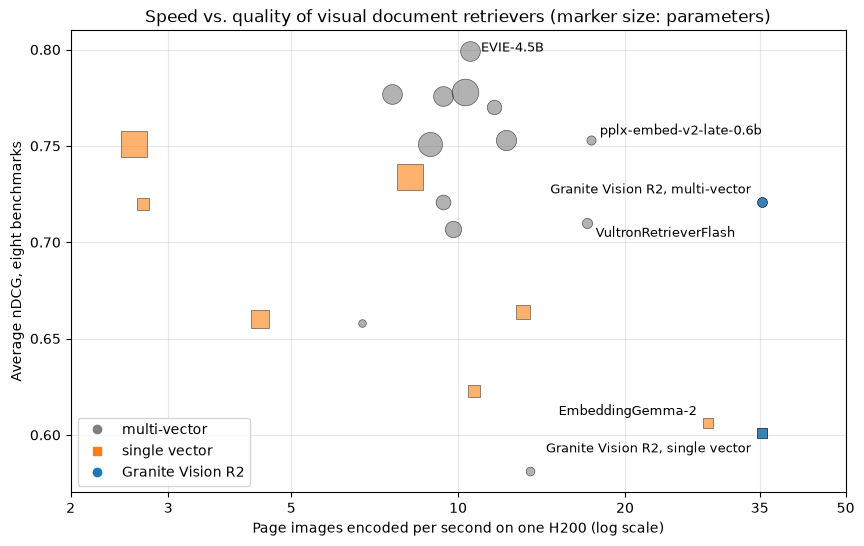

In [14]:
# (model, parameters in billions, mode, pages/s on one H200, average nDCG over eight benchmarks), from the model card.
reference = [
    ("ColUltraVBERT", 0.26, "MV", 6.7, 0.658), ("ColSmol-500M", 0.50, "MV", 13.5, 0.581),
    ("pplx-embed-v2-late-0.6b", 0.59, "MV", 17.4, 0.753), ("EmbeddingGemma-2", 0.74, "SV", 28.2, 0.606),
    ("VultronRetrieverFlash-Qwen3.5-0.8B", 0.85, "MV", 17.1, 0.710), ("Nemotron-3.5-Embed-1B", 1.55, "SV", 2.7, 0.720),
    ("jina-embeddings-v5-omni-small", 1.63, "SV", 10.7, 0.623), ("Qwen3-VL-Embedding-2B", 2.13, "SV", 13.1, 0.664),
    ("topk-embed-v1-small", 2.22, "MV", 11.6, 0.770), ("Argus-ColQwen3.5-2B", 2.32, "MV", 9.4, 0.721),
    ("ColQwen2.5-v0.2", 3.00, "MV", 9.8, 0.707), ("jina-embeddings-v4", 3.93, "SV", 4.4, 0.660),
    ("EVIE-4.5B", 4.54, "MV", 10.5, 0.799), ("webAI-ColVec1.1-4b", 4.54, "MV", 7.6, 0.777),
    ("VultronRetriever-Core-4.5B", 4.54, "MV", 9.4, 0.776), ("Nemotron-ColEmbed-VL-4B-v2", 4.80, "MV", 12.2, 0.753),
    ("ColNomic-Embed-Multimodal-7B", 7.00, "MV", 8.9, 0.751), ("Qwen3-VL-Embedding-8B", 8.14, "SV", 8.2, 0.734),
    ("Nemotron-3.5-Embed-8B", 8.38, "SV", 2.6, 0.751), ("Nemotron-ColEmbed-VL-8B-v2", 8.70, "MV", 10.3, 0.778),
    ("granite-embedding-748m-vision-r2 (MV)", 0.75, "MV", 35.3, 0.721),
    ("granite-embedding-748m-vision-r2 (SV)", 0.75, "SV", 35.3, 0.601),
]

from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FormatStrFormatter

labelled = {"granite-embedding-748m-vision-r2 (MV)": ("Granite Vision R2, multi-vector", (-8, 6), "right"),
            "granite-embedding-748m-vision-r2 (SV)": ("Granite Vision R2, single vector", (-8, -14), "right"),
            "pplx-embed-v2-late-0.6b": ("pplx-embed-v2-late-0.6b", (6, 4), "left"),
            "VultronRetrieverFlash-Qwen3.5-0.8B": ("VultronRetrieverFlash", (6, -10), "left"),
            "EmbeddingGemma-2": ("EmbeddingGemma-2", (-8, 6), "right"),
            "EVIE-4.5B": ("EVIE-4.5B", (8, 0), "left")}

fig, ax = plt.subplots(figsize=(10, 6))
for name, params, mode, speed, score in reference:
    granite = name.startswith("granite")
    ax.scatter(speed, score, s=40 * params + 20, marker="o" if mode == "MV" else "s",
               color="tab:blue" if granite else ("tab:gray" if mode == "MV" else "tab:orange"),
               alpha=0.9 if granite else 0.6, edgecolor="black", linewidth=0.5, zorder=3)
    if name in labelled:
        text, offset, align = labelled[name]
        ax.annotate(text, (speed, score), textcoords="offset points", xytext=offset, ha=align, fontsize=9)
ax.set_xscale("log")
ax.set_xlim(2, 50)
ax.xaxis.set_major_locator(FixedLocator([2, 3, 5, 10, 20, 35, 50]))
ax.xaxis.set_major_formatter(FormatStrFormatter("%g"))
ax.xaxis.set_minor_locator(FixedLocator([]))
ax.set_xlabel("Page images encoded per second on one H200 (log scale)")
ax.set_ylabel("Average nDCG, eight benchmarks")
ax.set_title("Speed vs. quality of visual document retrievers (marker size: parameters)")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="tab:gray", label="multi-vector"),
                   Line2D([], [], marker="s", ls="", color="tab:orange", label="single vector"),
                   Line2D([], [], marker="o", ls="", color="tab:blue", label="Granite Vision R2")], loc="lower left")
ax.grid(alpha=0.3)
plt.show()

In [15]:
# What a million pages costs on one H200, from the numbers above and the multi-vector index size per page.
# Granite stores about 149 KB per page; the model card reports pplx-embed-v2-late-0.6b at 2.5x that
# and VultronRetrieverFlash at 4.8x (more vectors per page, and 320 dimensions per vector for Vultron).
for name, speed, kb_per_page in [("granite-embedding-748m-vision-r2", 35.3, 149),
                                 ("pplx-embed-v2-late-0.6b", 17.4, 149 * 2.5),
                                 ("VultronRetrieverFlash-Qwen3.5-0.8B", 17.1, 149 * 4.8)]:
    # KB per page is GB per million pages.
    print(f"{name:<36} {1e6 / speed / 3600:5.1f} GPU-hours to encode, about {kb_per_page:4.0f} GB of multi-vectors")

granite-embedding-748m-vision-r2       7.9 GPU-hours to encode, about  149 GB of multi-vectors
pplx-embed-v2-late-0.6b               16.0 GPU-hours to encode, about  372 GB of multi-vectors
VultronRetrieverFlash-Qwen3.5-0.8B    16.2 GPU-hours to encode, about  715 GB of multi-vectors


## Next steps

- The [model card](https://huggingface.co/ibm-granite/granite-embedding-748m-vision-r2) has the full benchmark tables and the training details.
- `retrieval_example.py` and `maxsim_heatmap.py` in the model repository run the same examples from the command line; the heatmap script writes an interactive HTML page.